# Corn Disease Classification using EfficientNetV2S

**CropGuard AI: AI-Powered Crop Disease Detection and Advisory System**

Final Year Project, The Islamia University of Bahawalpur (IUB)

| | |
|---|---|
| Students | Muhammad Ali Ejaz, Ahmad Siddique |
| Supervisor | Dr. Faheem Mushtaq |
| Notebook | Corn model (one of six crop models: wheat, rice, cotton, sugarcane, potato, corn) |

## Overview

This notebook trains the corn (maize) disease classifier used in CropGuard AI. The model takes a photo of a corn leaf and predicts one of 6 classes (5 diseases plus healthy): Bacterial Leaf Streak, Common Rust, Gray Leaf Spot, Healthy, Leaf Blight / Leaf Spot and Maize Chlorotic Mottle Virus.

- **Dataset:** images from two sources are combined: the Seasonal Corn Leaf Disease Dataset from Mendeley Data (collected in Bangladesh) and the maize part of the CCMT crop pest and disease dataset from Kaggle. The insect pest folders of CCMT are not used, because they are not diseases. The CCMT leaf blight and leaf spot folders are merged into one class, and the CCMT streak virus folder is not used (see section 2.2).
- **Model:** EfficientNetV2S pre-trained on ImageNet, with a small classification head on top.
- **Training:** four phases with progressive unfreezing. The base model is frozen first, then unfrozen and trained with smaller and smaller learning rates.
- **Evaluation:** accuracy, per-class precision/recall/F1, confusion matrix and sample predictions on the validation set, and a final check on a separate test set.
- **Output:** the trained model and class files that are used by the CropGuard AI backend.

The notebook was run on Kaggle with a GPU.

**Before running:** Internet must be turned on in the notebook settings, because the Mendeley dataset is downloaded from the web (about 4 GB). The Kaggle dataset from section 1.2 must also be attached as input.

## 1. Setup

### 1.1 Libraries

In [1]:
import os
import glob
import json
import random
import shutil
import zipfile
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import EfficientNetV2S
from tensorflow.keras.applications.efficientnet_v2 import preprocess_input

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix

print("TensorFlow version:", tf.__version__)
print("GPUs available:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.20.0
GPUs available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


### 1.2 Configuration

All paths and main settings are kept in one place so they are easy to change.

In [2]:
# Sources
MENDELEY_URL = "https://data.mendeley.com/public-api/zip/vy629dngm8/download/1"
CCMT_MAIZE_DIR = Path("/kaggle/input/datasets/irakozekelly/crop-pest-and-disease-dataset/"
                      "Dataset for Crop Pest and Disease Detection/Raw Data/CCMT Dataset/Maize")

# Working folders
WORK_DIR = Path("/kaggle/working")
DOWNLOAD_ZIP = WORK_DIR / "bangladesh_corn.zip"
EXTRACT_DIR = WORK_DIR / "bangladesh_corn"            # temporary, deleted after extraction
BANGLADESH_DIR = WORK_DIR / "bangladesh_corn_final"
COMBINED_DIR = WORK_DIR / "combined_corn_dataset"     # both sources, one folder per class
SPLIT_DIR = WORK_DIR / "corn_split"                   # train / val / test
OUTPUT_DIR = "/kaggle/working"

# Data settings
IMG_SIZE = (384, 384)
BATCH_SIZE = 32
SPLIT_RATIOS = {"train": 0.70, "val": 0.15, "test": 0.15}
SEED = 42
IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png")

random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

## 2. Dataset Collection

### 2.1 Downloading the Mendeley dataset

The dataset is downloaded as a zip file. It contains another zip file inside, so it is extracted in two steps. The big files are deleted as soon as they are not needed, to save disk space on Kaggle.

In [3]:
!wget -q -O {DOWNLOAD_ZIP} "{MENDELEY_URL}"
print(f"Downloaded {DOWNLOAD_ZIP.name}: {DOWNLOAD_ZIP.stat().st_size / 1024 ** 3:.2f} GB")

Downloaded bangladesh_corn.zip: 4.28 GB


In [4]:
# Step 1: extract the outer zip, then delete it
!unzip -oq {DOWNLOAD_ZIP} -d {EXTRACT_DIR}
DOWNLOAD_ZIP.unlink()

inner_zips = glob.glob(f"{EXTRACT_DIR}/**/*.zip", recursive=True)
print("Inner zip found:", inner_zips)

Inner zip found: ['/kaggle/working/bangladesh_corn/Seasonal Corn Leaf Disease Dataset A Multi-Year Collection for Robust Analysis/Corn leaf disease dataset.zip']


In [5]:
# Step 2: extract the inner zip, then delete the temporary folder
!unzip -oq "{inner_zips[0]}" -d {BANGLADESH_DIR}
shutil.rmtree(EXTRACT_DIR)

BANGLADESH_ROOT = BANGLADESH_DIR / "Final corn dataset"
print("Mendeley classes:", sorted(os.listdir(BANGLADESH_ROOT)))
print("CCMT maize folders:", sorted(os.listdir(CCMT_MAIZE_DIR)))

Mendeley classes: ['Bacterial Leaf Streak', 'Common_rust', 'Gray_leaf_spot', 'Healthy', 'Maize Chlorotic Mottle Virus']
CCMT maize folders: ['fall armyworm', 'grasshoper', 'healthy', 'leaf beetle', 'leaf blight', 'leaf spot', 'streak virus']


### 2.2 Combining the two sources and choosing the classes

Each class folder of the two sources is mapped to one final class name. The Healthy class gets images from both sources, and the other classes come from one source each. A prefix (`bd` for Mendeley and `ccmt` for CCMT) is added to every file name so that files never overwrite each other.

The classes were chosen to fit the use of the app in Pakistan:

- The CCMT folders `leaf blight` and `leaf spot` are merged into one class, `Leaf_blight_spot`. The two diseases look similar, both make brown lesions on the leaf, and in earlier training runs the model often confused them.
- The CCMT folder `streak virus` is not used. Maize streak virus occurs mainly in Africa and is not relevant for farmers in Pakistan.
- The CCMT folders `fall armyworm`, `grasshoper` and `leaf beetle` are insects, not diseases, so they are skipped.

In [6]:
# final class name -> list of (source folder, file name prefix)
class_map = {
    "Healthy": [
        (BANGLADESH_ROOT / "Healthy", "bd"),
        (CCMT_MAIZE_DIR / "healthy", "ccmt"),
    ],
    "Bacterial_Leaf_Streak": [(BANGLADESH_ROOT / "Bacterial Leaf Streak", "bd")],
    "Common_rust": [(BANGLADESH_ROOT / "Common_rust", "bd")],
    "Gray_leaf_spot": [(BANGLADESH_ROOT / "Gray_leaf_spot", "bd")],
    "Maize_Chlorotic_Mottle_Virus": [(BANGLADESH_ROOT / "Maize Chlorotic Mottle Virus", "bd")],
    "Leaf_blight_spot": [
        (CCMT_MAIZE_DIR / "leaf blight", "ccmt_blight"),
        (CCMT_MAIZE_DIR / "leaf spot", "ccmt_spot"),
    ],
}

COMBINED_DIR.mkdir(parents=True, exist_ok=True)

for class_name, class_sources in class_map.items():
    dest_dir = COMBINED_DIR / class_name
    dest_dir.mkdir(parents=True, exist_ok=True)
    count = 0
    for src_dir, prefix in class_sources:
        if not src_dir.exists():
            print(f"Not found: {src_dir}")
            continue
        for f in src_dir.iterdir():
            if f.is_file():
                shutil.copy(f, dest_dir / f"{prefix}_{f.name}")
                count += 1
    print(f"{class_name}: {count} images")

# the Mendeley files are copied now, so the extracted folder is not needed any more
shutil.rmtree(BANGLADESH_DIR)

Healthy: 1246 images
Bacterial_Leaf_Streak: 190 images
Common_rust: 129 images
Gray_leaf_spot: 1497 images
Maize_Chlorotic_Mottle_Virus: 89 images
Leaf_blight_spot: 2265 images


### 2.3 Class distribution

Total: 5416 images in 6 classes


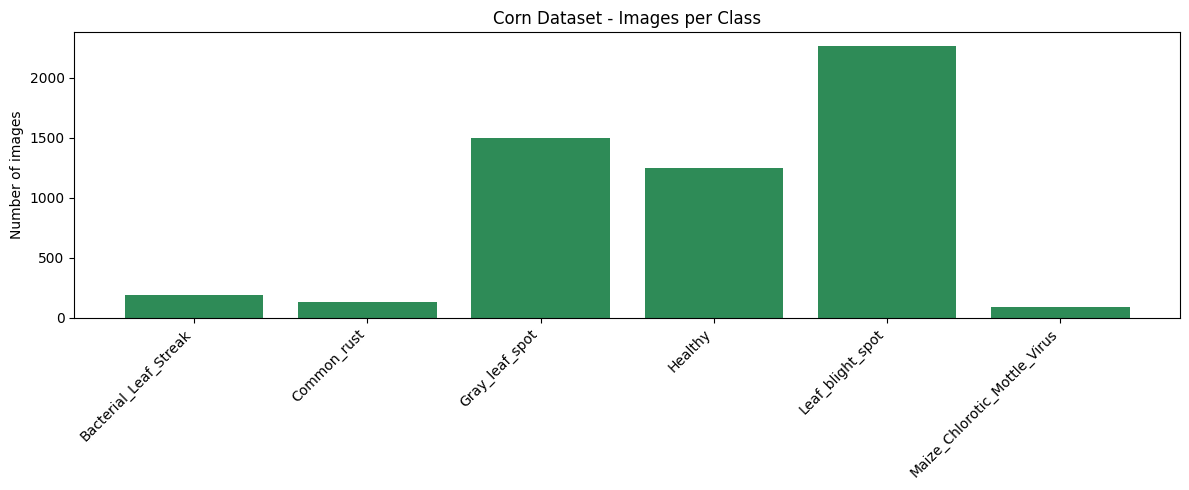

In [7]:
def count_images(folder):
    return len([f for f in os.listdir(folder) if f.lower().endswith(IMAGE_EXTENSIONS)])


class_counts = {d.name: count_images(d) for d in sorted(COMBINED_DIR.iterdir()) if d.is_dir()}

print(f"Total: {sum(class_counts.values())} images in {len(class_counts)} classes")

plt.figure(figsize=(12, 5))
plt.bar(class_counts.keys(), class_counts.values(), color="seagreen")
plt.xticks(rotation=45, ha="right")
plt.ylabel("Number of images")
plt.title("Corn Dataset - Images per Class")
plt.tight_layout()
plt.show()

The classes are very unbalanced. Maize Chlorotic Mottle Virus, Common Rust and Bacterial Leaf Streak have far fewer images than the other classes, so class weights are used during training (section 4).

### 2.4 Splitting into train, validation and test

Each class is shuffled with a fixed seed and split 70% / 15% / 15% into train, validation and test sets. Symbolic links are used instead of copies, which saves disk space. The test set is not used during training. It is only used for the final check in section 8.3.

In [8]:
for class_dir in sorted(COMBINED_DIR.iterdir()):
    if not class_dir.is_dir():
        continue

    files = sorted(class_dir.iterdir())     # sorted first, so the shuffle is the same on every run
    random.shuffle(files)

    n = len(files)
    n_train = int(n * SPLIT_RATIOS["train"])
    n_val = int(n * SPLIT_RATIOS["val"])

    split_files = {
        "train": files[:n_train],
        "val": files[n_train:n_train + n_val],
        "test": files[n_train + n_val:],
    }

    for split_name, file_list in split_files.items():
        dest = SPLIT_DIR / split_name / class_dir.name
        dest.mkdir(parents=True, exist_ok=True)
        for f in file_list:
            link_path = dest / f.name
            if not link_path.exists():
                os.symlink(f.resolve(), link_path)

    print(f"{class_dir.name}: train={len(split_files['train'])}, "
          f"val={len(split_files['val'])}, test={len(split_files['test'])}")

Bacterial_Leaf_Streak: train=133, val=28, test=29
Common_rust: train=90, val=19, test=20
Gray_leaf_spot: train=1047, val=224, test=226
Healthy: train=872, val=186, test=188
Leaf_blight_spot: train=1585, val=339, test=341
Maize_Chlorotic_Mottle_Virus: train=62, val=13, test=14


### 2.5 Removing corrupt images

Every image in the three splits is opened with PIL. Files that cannot be read completely (for example truncated downloads) are removed. The splits only contain links, so only the link is deleted.

In [9]:
bad_files = []

for split in ["train", "val", "test"]:
    for class_dir in (SPLIT_DIR / split).iterdir():
        if not class_dir.is_dir():
            continue
        for f in class_dir.iterdir():
            try:
                img = Image.open(f)
                img.verify()               # quick integrity check
                img = Image.open(f)
                img.load()                 # full decode, catches truncated files
            except Exception:
                bad_files.append(f)

for f in bad_files:
    f.unlink()

print(f"Removed {len(bad_files)} corrupt images")

Removed 40 corrupt images


In [10]:
print(f"{'class':32s} {'train':>6s} {'val':>6s} {'test':>6s}")
for class_dir in sorted((SPLIT_DIR / "train").iterdir()):
    row = [count_images(SPLIT_DIR / split / class_dir.name) for split in ["train", "val", "test"]]
    print(f"{class_dir.name:32s} {row[0]:6d} {row[1]:6d} {row[2]:6d}")

class                             train    val   test
Bacterial_Leaf_Streak               133     28     29
Common_rust                          90     19     20
Gray_leaf_spot                     1047    224    226
Healthy                             870    186    186
Leaf_blight_spot                   1558    336    335
Maize_Chlorotic_Mottle_Virus         62     13     14


## 3. Loading the Data

`image_dataset_from_directory` reads the train and validation folders. The class names are taken from the folder names.

In [11]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    str(SPLIT_DIR / "train"), image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="categorical", seed=SEED
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    str(SPLIT_DIR / "val"), image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="categorical", seed=SEED
)

class_names = train_ds.class_names
NUM_CLASSES = len(class_names)
print("Classes:", class_names)
print("Number of classes:", NUM_CLASSES)

Found 3760 files belonging to 6 classes.


I0000 00:00:1793100036.188776      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1793100036.197896      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Found 806 files belonging to 6 classes.
Classes: ['Bacterial_Leaf_Streak', 'Common_rust', 'Gray_leaf_spot', 'Healthy', 'Leaf_blight_spot', 'Maize_Chlorotic_Mottle_Virus']
Number of classes: 6


## 4. Class Weights

Because of the class imbalance, each class gets a weight that is higher for smaller classes. This makes mistakes on rare classes cost more during training. The weights are calculated from the training split.

In [12]:
labels_flat = []
for i, cls in enumerate(class_names):
    labels_flat.extend([i] * count_images(SPLIT_DIR / "train" / cls))
labels_flat = np.array(labels_flat)

cw_values = compute_class_weight("balanced", classes=np.unique(labels_flat), y=labels_flat)
class_weight_dict = {i: w for i, w in enumerate(cw_values)}

for i, cls in enumerate(class_names):
    print(f"{cls}: {class_weight_dict[i]:.3f}")

Bacterial_Leaf_Streak: 4.712
Common_rust: 6.963
Gray_leaf_spot: 0.599
Healthy: 0.720
Leaf_blight_spot: 0.402
Maize_Chlorotic_Mottle_Virus: 10.108


## 5. Preprocessing

No augmentation is applied in this notebook. The images are only passed through the EfficientNetV2S preprocessing function.

In [13]:
def prep(img, lbl):
    return preprocess_input(img), lbl


train_ds_p = train_ds.map(prep, num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)
val_ds_p = val_ds.map(prep, num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)

## 6. Model

EfficientNetV2S is used as the base model with ImageNet weights and without its original top layer. On top of it we add:

- Global average pooling to turn the feature maps into one vector
- Batch normalization
- Dropout (0.4) to reduce overfitting
- A dense softmax layer with one output per class

The base model starts frozen so that only the new head is trained in the first phase.

In [14]:
base = EfficientNetV2S(include_top=False, weights="imagenet", input_shape=(384, 384, 3))
base.trainable = False

inputs = keras.Input(shape=(384, 384, 3))
x = base(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.4)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
model = keras.Model(inputs, outputs)

model.summary()

82420632/82420632 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 384, 384, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetv2-s (Functional)   │ (None, 12, 12, 1280)   │    20,331,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,344,166 (77.61 MB)

 Trainable params: 10,246 (40.02 KB)

 Non-trainable params: 20,333,920 (77.57 MB)

### 6.1 Callbacks

- **EarlyStopping:** stops a phase when validation accuracy stops improving and goes back to the best weights.
- **ModelCheckpoint:** saves the model with the best validation accuracy to `best_corn_model.keras`.
- **ReduceLROnPlateau:** lowers the learning rate when validation loss stops improving.
- **BackupAndRestore:** saves training progress so a crashed session can continue.

The same list is used for phases 1 to 3. In phase 4 the early stopping callback is replaced by one with more patience.

In [15]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=3, restore_best_weights=True),
    keras.callbacks.ModelCheckpoint(f"{OUTPUT_DIR}/best_corn_model.keras", monitor="val_accuracy", save_best_only=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2, min_lr=1e-7),
    keras.callbacks.BackupAndRestore(f"{OUTPUT_DIR}/corn_backup/")
]

## 7. Training

Training is done in four phases. The learning rate gets smaller in every phase, so the pre-trained weights are changed gently once the base model is unfrozen.

| Phase | Base model | Learning rate | Max epochs |
|---|---|---|---|
| 1 | Frozen | 1e-3 | 10 |
| 2 | Fully unfrozen | 1e-4 | 10 |
| 3 | Fully unfrozen | 5e-5 | 15 |
| 4 | Fully unfrozen (best weights reloaded) | 1e-5 | 15 |

### Phase 1: Frozen base

Only the new classification head is trained. This gives the head sensible weights before the base model is touched.

In [16]:
model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="categorical_crossentropy", metrics=["accuracy"])

h1 = model.fit(train_ds_p, validation_data=val_ds_p, epochs=10,
               class_weight=class_weight_dict, callbacks=callbacks)

print(f"Phase 1 best validation accuracy: {max(h1.history['val_accuracy']) * 100:.2f}%")

Epoch 1/10


2026-10-27 11:21:25.012714: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 11:21:25.181893: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 11:21:26.349643: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 11:21:26.529676: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 11:21:28.220636: E external/local_xla/xla/stream_

117/118 ━━━━━━━━━━━━━━━━━━━━ 0s 322ms/step - accuracy: 0.4686 - loss: 1.5130

2026-10-27 11:22:36.583355: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 11:22:36.731259: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 11:22:37.691677: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 11:22:37.844457: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 11:22:39.404056: E external/local_xla/xla/stream_

118/118 ━━━━━━━━━━━━━━━━━━━━ 0s 603ms/step - accuracy: 0.4697 - loss: 1.5088

2026-10-27 11:23:25.918156: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 11:23:26.056235: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 11:23:26.891954: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 11:23:27.033169: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 11:23:28.461233: E external/local_xla/xla/stream_

118/118 ━━━━━━━━━━━━━━━━━━━━ 175s 946ms/step - accuracy: 0.5976 - loss: 1.0110 - val_accuracy: 0.8424 - val_loss: 0.7576 - learning_rate: 0.0010
Epoch 2/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 54s 453ms/step - accuracy: 0.7968 - loss: 0.4469 - val_accuracy: 0.9293 - val_loss: 0.4009 - learning_rate: 0.0010
Epoch 3/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 54s 452ms/step - accuracy: 0.8471 - loss: 0.3346 - val_accuracy: 0.9380 - val_loss: 0.2463 - learning_rate: 0.0010
Epoch 4/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 53s 447ms/step - accuracy: 0.8729 - loss: 0.2640 - val_accuracy: 0.9429 - val_loss: 0.2032 - learning_rate: 0.0010
Epoch 5/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 52s 436ms/step - accuracy: 0.8787 - loss: 0.2506 - val_accuracy: 0.9342 - val_loss: 0.1937 - learning_rate: 0.0010
Epoch 6/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 54s 451ms/step - accuracy: 0.8931 - loss: 0.2059 - val_accuracy: 0.9491 - val_loss: 0.1830 - learning_rate: 0.0010
Epoch 7/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 54s 452ms/step - accuracy: 0.8989 - loss

### Phase 2: Full fine-tuning (lr = 1e-4)

The whole base model is unfrozen so the pre-trained features can adapt to corn leaves.

In [17]:
base.trainable = True

model.compile(optimizer=keras.optimizers.Adam(1e-4),
              loss="categorical_crossentropy", metrics=["accuracy"])

h2 = model.fit(train_ds_p, validation_data=val_ds_p, epochs=10,
               class_weight=class_weight_dict, callbacks=callbacks)

print(f"Phase 2 best validation accuracy: {max(h2.history['val_accuracy']) * 100:.2f}%")

Epoch 1/10


2026-10-27 11:33:36.896104: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 11:33:37.085498: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 11:33:43.270209: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 11:33:43.457042: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 11:33:46.264020: E external/local_xla/xla/stream_

117/118 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 0.7749 - loss: 0.7410

2026-10-27 11:37:13.497617: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 11:37:13.654186: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 11:37:16.995543: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 11:37:17.164157: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 11:37:18.600011: E external/local_xla/xla/stream_

118/118 ━━━━━━━━━━━━━━━━━━━━ 411s 2s/step - accuracy: 0.8359 - loss: 0.4341 - val_accuracy: 0.9615 - val_loss: 0.1394 - learning_rate: 1.0000e-04
Epoch 2/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 133s 1s/step - accuracy: 0.9372 - loss: 0.1219 - val_accuracy: 0.9752 - val_loss: 0.0973 - learning_rate: 1.0000e-04
Epoch 3/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 141s 1s/step - accuracy: 0.9593 - loss: 0.0943 - val_accuracy: 0.9777 - val_loss: 0.1003 - learning_rate: 1.0000e-04
Epoch 4/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 130s 1s/step - accuracy: 0.9779 - loss: 0.0415 - val_accuracy: 0.9739 - val_loss: 0.1067 - learning_rate: 1.0000e-04
Epoch 5/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 132s 1s/step - accuracy: 0.9827 - loss: 0.0351 - val_accuracy: 0.9789 - val_loss: 0.0955 - learning_rate: 3.0000e-05
Epoch 6/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 129s 1s/step - accuracy: 0.9827 - loss: 0.0327 - val_accuracy: 0.9777 - val_loss: 0.0935 - learning_rate: 3.0000e-05
Epoch 7/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 130s 1s/step - accuracy: 0.98

### Phase 3: Full fine-tuning (lr = 5e-5)

Training continues with a different learning rate for finer updates.

In [18]:
model.compile(optimizer=keras.optimizers.Adam(5e-5),
              loss="categorical_crossentropy", metrics=["accuracy"])

h3 = model.fit(train_ds_p, validation_data=val_ds_p, epochs=15,
               class_weight=class_weight_dict, callbacks=callbacks)

print(f"Phase 3 best validation accuracy: {max(h3.history['val_accuracy']) * 100:.2f}%")

Epoch 1/15
118/118 ━━━━━━━━━━━━━━━━━━━━ 373s 2s/step - accuracy: 0.9782 - loss: 0.0458 - val_accuracy: 0.9789 - val_loss: 0.1139 - learning_rate: 5.0000e-05
Epoch 2/15
118/118 ━━━━━━━━━━━━━━━━━━━━ 130s 1s/step - accuracy: 0.9859 - loss: 0.0295 - val_accuracy: 0.9789 - val_loss: 0.1045 - learning_rate: 5.0000e-05
Epoch 3/15
118/118 ━━━━━━━━━━━━━━━━━━━━ 133s 1s/step - accuracy: 0.9883 - loss: 0.0150 - val_accuracy: 0.9801 - val_loss: 0.1004 - learning_rate: 1.5000e-05
Epoch 4/15
118/118 ━━━━━━━━━━━━━━━━━━━━ 133s 1s/step - accuracy: 0.9907 - loss: 0.0192 - val_accuracy: 0.9826 - val_loss: 0.0883 - learning_rate: 1.5000e-05
Epoch 5/15
118/118 ━━━━━━━━━━━━━━━━━━━━ 131s 1s/step - accuracy: 0.9923 - loss: 0.0110 - val_accuracy: 0.9826 - val_loss: 0.0860 - learning_rate: 1.5000e-05
Epoch 6/15
118/118 ━━━━━━━━━━━━━━━━━━━━ 130s 1s/step - accuracy: 0.9931 - loss: 0.0134 - val_accuracy: 0.9777 - val_loss: 0.1010 - learning_rate: 1.5000e-05
Epoch 7/15
118/118 ━━━━━━━━━━━━━━━━━━━━ 143s 1s/step - acc

### Phase 4: Final polish (lr = 1e-5)

The best weights saved so far are loaded again and trained with a very small learning rate and more patience (5 epochs), to squeeze out the last bit of accuracy.

In [19]:
model.load_weights(f"{OUTPUT_DIR}/best_corn_model.keras")

callbacks[0] = keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=5, restore_best_weights=True)

model.compile(optimizer=keras.optimizers.Adam(1e-5),
              loss="categorical_crossentropy", metrics=["accuracy"])

h4 = model.fit(train_ds_p, validation_data=val_ds_p, epochs=15,
               class_weight=class_weight_dict, callbacks=callbacks)

print(f"Phase 4 best validation accuracy: {max(h4.history['val_accuracy']) * 100:.2f}%")

Epoch 1/15
118/118 ━━━━━━━━━━━━━━━━━━━━ 378s 2s/step - accuracy: 0.9928 - loss: 0.0158 - val_accuracy: 0.9826 - val_loss: 0.0922 - learning_rate: 1.0000e-05
Epoch 2/15
118/118 ━━━━━━━━━━━━━━━━━━━━ 131s 1s/step - accuracy: 0.9957 - loss: 0.0082 - val_accuracy: 0.9826 - val_loss: 0.0875 - learning_rate: 1.0000e-05
Epoch 3/15
118/118 ━━━━━━━━━━━━━━━━━━━━ 128s 1s/step - accuracy: 0.9896 - loss: 0.0148 - val_accuracy: 0.9826 - val_loss: 0.0903 - learning_rate: 3.0000e-06
Epoch 4/15
118/118 ━━━━━━━━━━━━━━━━━━━━ 132s 1s/step - accuracy: 0.9939 - loss: 0.0110 - val_accuracy: 0.9839 - val_loss: 0.0960 - learning_rate: 3.0000e-06
Epoch 5/15
118/118 ━━━━━━━━━━━━━━━━━━━━ 129s 1s/step - accuracy: 0.9941 - loss: 0.0079 - val_accuracy: 0.9826 - val_loss: 0.0947 - learning_rate: 9.0000e-07
Epoch 6/15
118/118 ━━━━━━━━━━━━━━━━━━━━ 130s 1s/step - accuracy: 0.9963 - loss: 0.0065 - val_accuracy: 0.9826 - val_loss: 0.0866 - learning_rate: 9.0000e-07
Epoch 7/15
118/118 ━━━━━━━━━━━━━━━━━━━━ 130s 1s/step - acc

### 7.1 Training curves

The plots below join all four phases. The dashed vertical lines show where a new phase starts.

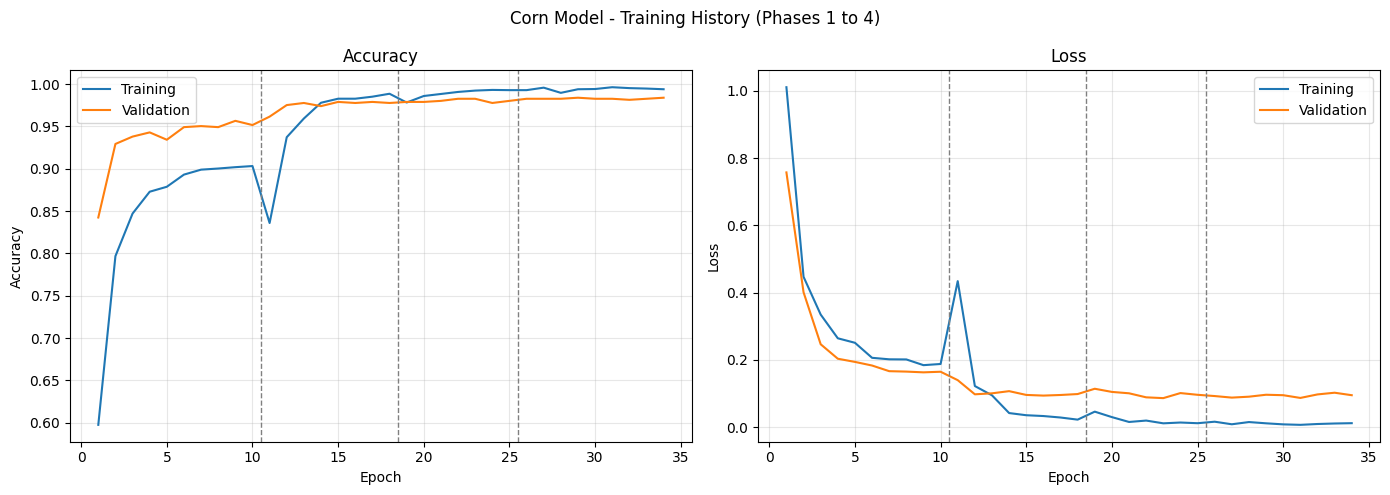

In [20]:
histories = [h1, h2, h3, h4]

train_acc, val_acc, train_loss, val_loss = [], [], [], []
phase_ends = []
for h in histories:
    train_acc += h.history["accuracy"]
    val_acc += h.history["val_accuracy"]
    train_loss += h.history["loss"]
    val_loss += h.history["val_loss"]
    phase_ends.append(len(train_acc))

epochs_range = range(1, len(train_acc) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(epochs_range, train_acc, label="Training")
axes[0].plot(epochs_range, val_acc, label="Validation")
axes[0].set_title("Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")

axes[1].plot(epochs_range, train_loss, label="Training")
axes[1].plot(epochs_range, val_loss, label="Validation")
axes[1].set_title("Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")

for ax in axes:
    for end in phase_ends[:-1]:
        ax.axvline(end + 0.5, color="gray", linestyle="--", linewidth=1)
    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle("Corn Model - Training History (Phases 1 to 4)")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/corn_training_curves.png", dpi=150)
plt.show()

## 8. Evaluation

### 8.1 Validation set

The model is first evaluated on the validation set. Precision, recall and F1-score are reported for every class, followed by the confusion matrix. The validation set was also used to choose the best epoch, so the separate test set in section 8.3 gives a fairer final number.

In [21]:
y_true, y_pred = [], []
for imgs, lbls in val_ds_p:
    preds = model.predict(imgs, verbose=0)
    y_true.extend(np.argmax(lbls.numpy(), axis=1))
    y_pred.extend(np.argmax(preds, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

val_accuracy = np.mean(y_true == y_pred)
print(f"Validation accuracy: {val_accuracy * 100:.2f}%  ({len(y_true)} images)\n")
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

Validation accuracy: 98.39%  (806 images)

                              precision    recall  f1-score   support

       Bacterial_Leaf_Streak     1.0000    1.0000    1.0000        28
                 Common_rust     1.0000    1.0000    1.0000        19
              Gray_leaf_spot     0.9955    0.9777    0.9865       224
                     Healthy     0.9534    0.9892    0.9710       186
            Leaf_blight_spot     0.9940    0.9821    0.9880       336
Maize_Chlorotic_Mottle_Virus     0.9286    1.0000    0.9630        13

                    accuracy                         0.9839       806
                   macro avg     0.9786    0.9915    0.9847       806
                weighted avg     0.9843    0.9839    0.9840       806



The classification report shows how well each class is predicted. Classes with lower scores are usually the ones with symptoms that look similar to other classes, and the confusion matrix below shows which classes get mixed up.

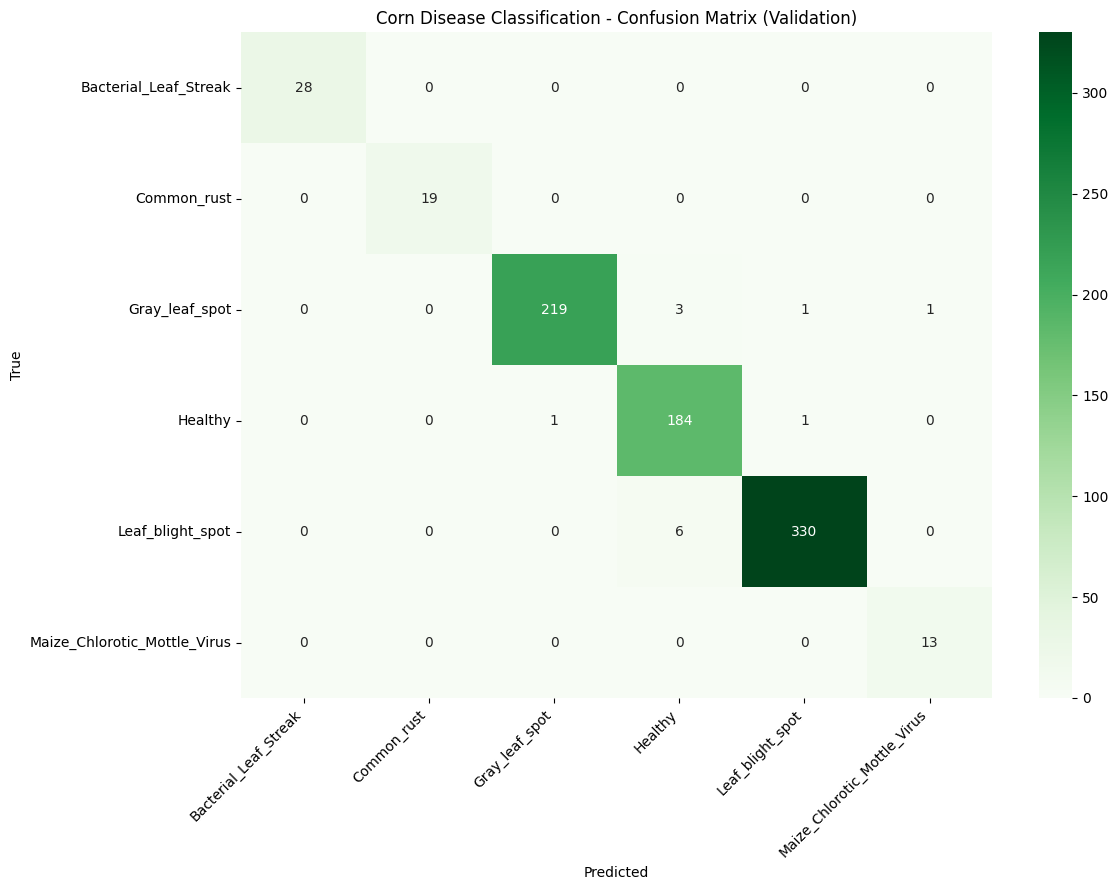

In [22]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(12, 9))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Corn Disease Classification - Confusion Matrix (Validation)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/corn_confusion_matrix.png", dpi=150)
plt.show()

### 8.2 Sample predictions

A batch of validation images with the true label, the predicted label and the model's confidence. Green titles are correct predictions and red titles are mistakes.

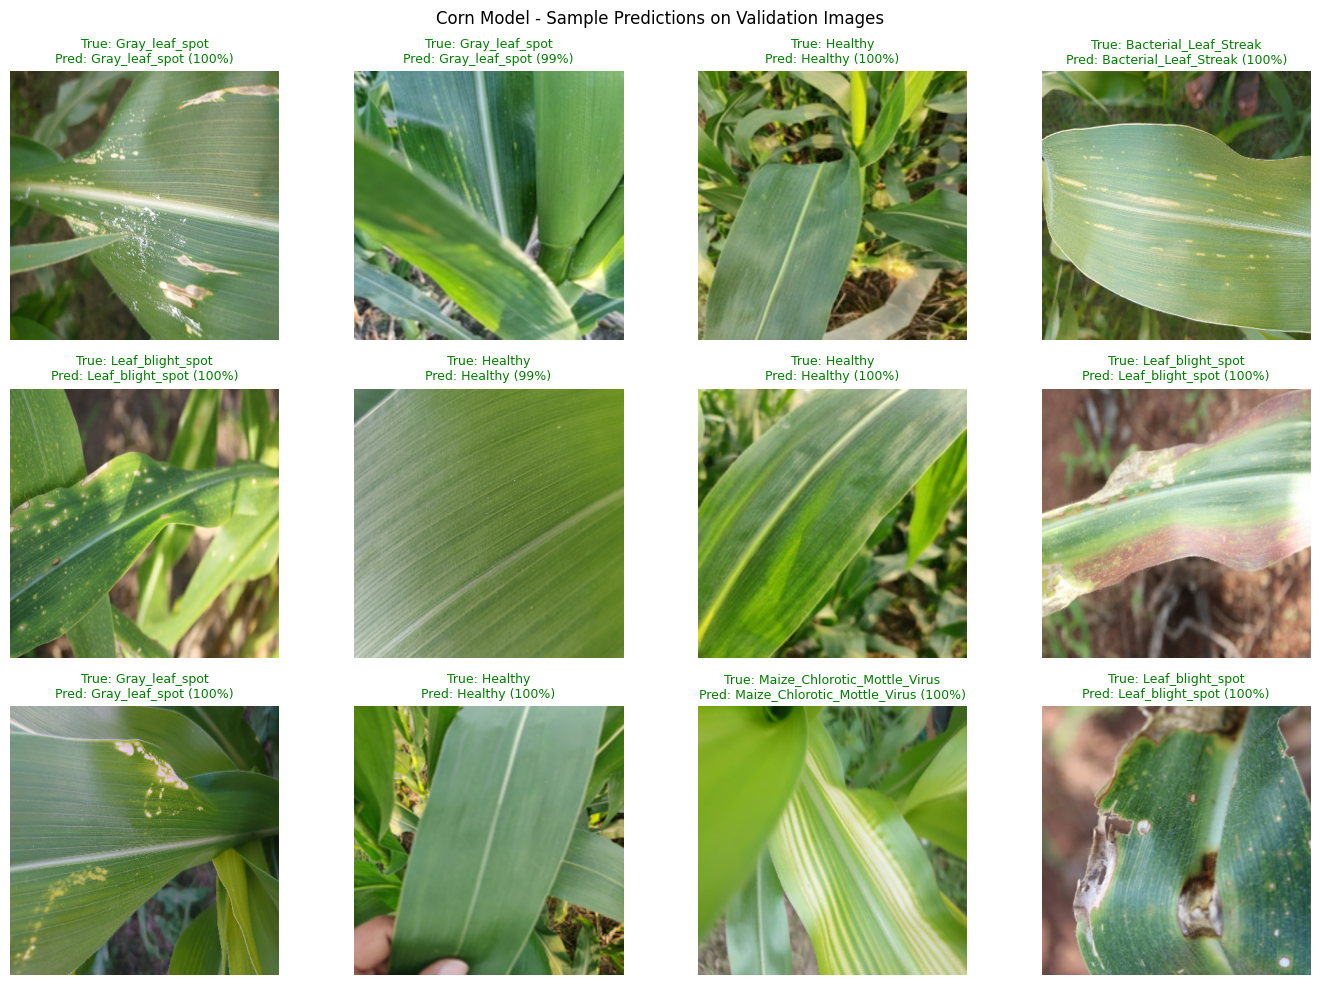

In [23]:
sample_images, sample_labels = next(iter(val_ds))
sample_probs = model.predict(preprocess_input(sample_images), verbose=0)

sample_true = np.argmax(sample_labels.numpy(), axis=1)
sample_pred = np.argmax(sample_probs, axis=1)

plt.figure(figsize=(14, 10))
for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(sample_images[i].numpy().astype("uint8"))
    plt.axis("off")

    confidence = sample_probs[i][sample_pred[i]] * 100
    correct = sample_true[i] == sample_pred[i]
    plt.title(f"True: {class_names[sample_true[i]]}\nPred: {class_names[sample_pred[i]]} ({confidence:.0f}%)",
              fontsize=9, color="green" if correct else "red")

plt.suptitle("Corn Model - Sample Predictions on Validation Images")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/corn_sample_predictions.png", dpi=150)
plt.show()

### 8.3 Test set

The test split (15% of the images) was not used for training or for choosing the best epoch, so this is the fairest estimate of how the model works on new images. The test set is only used here, once.

In [24]:
test_ds = tf.keras.utils.image_dataset_from_directory(
    str(SPLIT_DIR / "test"), image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="categorical", shuffle=False
)
assert test_ds.class_names == class_names, "test classes do not match train classes"

test_ds_p = test_ds.map(prep, num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)

y_true_test, y_pred_test = [], []
for imgs, lbls in test_ds_p:
    preds = model.predict(imgs, verbose=0)
    y_true_test.extend(np.argmax(lbls.numpy(), axis=1))
    y_pred_test.extend(np.argmax(preds, axis=1))

y_true_test = np.array(y_true_test)
y_pred_test = np.array(y_pred_test)

test_accuracy = np.mean(y_true_test == y_pred_test)
print(f"Test accuracy: {test_accuracy * 100:.2f}%  ({len(y_true_test)} images)\n")
print(classification_report(y_true_test, y_pred_test, target_names=class_names, digits=4))

Found 810 files belonging to 6 classes.


2026-10-27 12:38:43.963911: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 12:38:44.106334: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 12:38:45.008721: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 12:38:45.155202: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 12:38:46.686858: E external/local_xla/xla/stream_

Test accuracy: 97.53%  (810 images)

                              precision    recall  f1-score   support

       Bacterial_Leaf_Streak     0.9667    1.0000    0.9831        29
                 Common_rust     1.0000    1.0000    1.0000        20
              Gray_leaf_spot     1.0000    0.9602    0.9797       226
                     Healthy     0.9524    0.9677    0.9600       186
            Leaf_blight_spot     0.9792    0.9851    0.9821       335
Maize_Chlorotic_Mottle_Virus     0.8235    1.0000    0.9032        14

                    accuracy                         0.9753       810
                   macro avg     0.9536    0.9855    0.9680       810
                weighted avg     0.9762    0.9753    0.9755       810



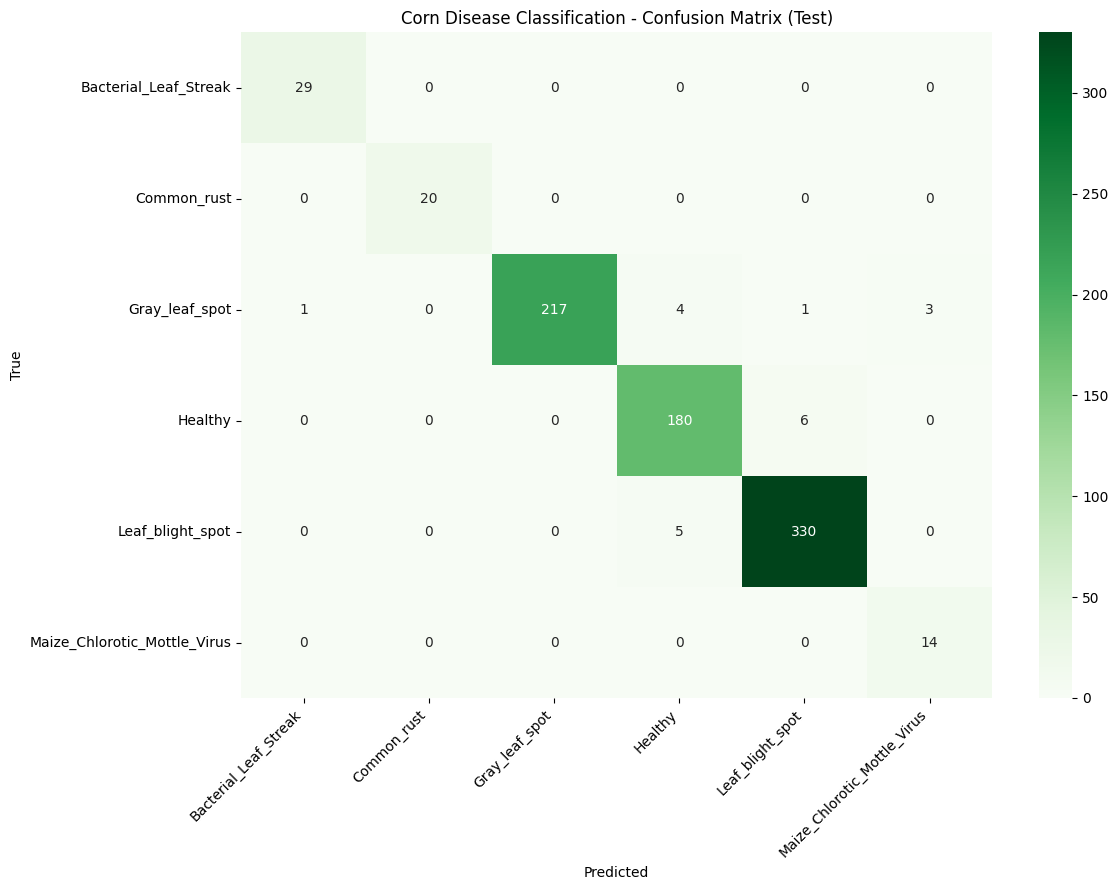

In [25]:
cm_test = confusion_matrix(y_true_test, y_pred_test)

plt.figure(figsize=(12, 9))
sns.heatmap(cm_test, annot=True, fmt="d", cmap="Greens",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Corn Disease Classification - Confusion Matrix (Test)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/corn_test_confusion_matrix.png", dpi=150)
plt.show()

## 9. Saving the Model

The final model is saved together with two JSON files that the CropGuard AI backend needs:

- `corn_class_names.json`: the class labels in the same order as the model outputs, in the form `corn__<disease>`
- `corn_class_map.json`: maps each label to the crop name and a readable disease name

Everything is then packed into one zip file.

In [26]:
model.save(f"{OUTPUT_DIR}/corn_final.keras")
size_mb = os.path.getsize(f"{OUTPUT_DIR}/corn_final.keras") / 1024 / 1024
print(f"Model saved ({size_mb:.1f} MB)")

Model saved (233.7 MB)


In [27]:
DISEASE_NAMES = {
    "Bacterial_Leaf_Streak": "Bacterial Leaf Streak",
    "Common_rust": "Common Rust",
    "Gray_leaf_spot": "Gray Leaf Spot",
    "Healthy": "Healthy",
    "Leaf_blight_spot": "Leaf Blight / Leaf Spot",
    "Maize_Chlorotic_Mottle_Virus": "Maize Chlorotic Mottle Virus",
}

corn_class_map = {}
production_class_names = []

for cls in class_names:
    key = "corn__" + cls.lower()
    production_class_names.append(key)
    corn_class_map[key] = {"crop": "Corn", "disease": DISEASE_NAMES.get(cls, cls)}

with open(f"{OUTPUT_DIR}/corn_class_map.json", "w") as f:
    json.dump(corn_class_map, f, indent=2)
with open(f"{OUTPUT_DIR}/corn_class_names.json", "w") as f:
    json.dump(production_class_names, f, indent=2)

print(json.dumps(corn_class_map, indent=2))

{
  "corn__bacterial_leaf_streak": {
    "crop": "Corn",
    "disease": "Bacterial Leaf Streak"
  },
  "corn__common_rust": {
    "crop": "Corn",
    "disease": "Common Rust"
  },
  "corn__gray_leaf_spot": {
    "crop": "Corn",
    "disease": "Gray Leaf Spot"
  },
  "corn__healthy": {
    "crop": "Corn",
    "disease": "Healthy"
  },
  "corn__leaf_blight_spot": {
    "crop": "Corn",
    "disease": "Leaf Blight / Leaf Spot"
  },
  "corn__maize_chlorotic_mottle_virus": {
    "crop": "Corn",
    "disease": "Maize Chlorotic Mottle Virus"
  }
}


In [28]:
files = [
    f"{OUTPUT_DIR}/corn_final.keras",
    f"{OUTPUT_DIR}/best_corn_model.keras",
    f"{OUTPUT_DIR}/corn_class_map.json",
    f"{OUTPUT_DIR}/corn_class_names.json",
    f"{OUTPUT_DIR}/corn_confusion_matrix.png",
    f"{OUTPUT_DIR}/corn_test_confusion_matrix.png",
    f"{OUTPUT_DIR}/corn_training_curves.png",
    f"{OUTPUT_DIR}/corn_sample_predictions.png",
]

zip_path = f"{OUTPUT_DIR}/corn_model_package.zip"
with zipfile.ZipFile(zip_path, "w") as zf:
    for f in files:
        if os.path.exists(f):
            zf.write(f, arcname=os.path.basename(f))
            print(f"added {os.path.basename(f)} ({os.path.getsize(f) / 1024 / 1024:.1f} MB)")
        else:
            print(f"missing: {f}")

print(f"\nPackage: {zip_path} ({os.path.getsize(zip_path) / 1024 / 1024:.1f} MB)")

added corn_final.keras (233.7 MB)
added best_corn_model.keras (233.7 MB)
added corn_class_map.json (0.0 MB)
added corn_class_names.json (0.0 MB)
added corn_confusion_matrix.png (0.1 MB)
added corn_test_confusion_matrix.png (0.1 MB)
added corn_training_curves.png (0.1 MB)
added corn_sample_predictions.png (3.0 MB)

Package: /kaggle/working/corn_model_package.zip (470.7 MB)


## 10. Summary and Limitations

**Summary**

- Corn leaf images from the Mendeley Seasonal Corn Leaf Disease Dataset and the CCMT maize dataset were combined and used to fine-tune an EfficientNetV2S model for 6 classes, using four training phases with decreasing learning rates.
- The data was split 70% / 15% / 15% into train, validation and test sets. Class weights were used to handle the imbalance between classes.
- The validation accuracy, per-class scores, confusion matrix and sample predictions are shown in sections 8.1 and 8.2, and the result on the separate test set is in section 8.3.
- The saved model and class files are used in the CropGuard AI website and mobile app.

**Limitations**

- The validation set was used for early stopping and for choosing the best checkpoint, so the validation accuracy can be slightly higher than the true accuracy. The test set result is the fairer number.
- Five of the six classes come from only one of the two sources. Only Healthy has images from both. The sources were collected with different cameras and backgrounds, so the model may partly learn the style of a source instead of only the disease.
- Leaf Blight and Leaf Spot are one class, so the model cannot tell them apart. Streak virus is not included, so a leaf with that disease will be wrongly assigned to one of the other classes.
- The images were split randomly without checking for duplicates. If very similar images (for example several photos of the same plant) exist, some of them can end up in both training and validation or test, which makes the accuracy look better than it really is.
- Maize Chlorotic Mottle Virus, Common Rust and Bacterial Leaf Streak have only a few images in the validation and test sets, so their scores are not very reliable.
- The classes were chosen for use in Pakistan, not for accuracy, so the results cannot be compared directly with a model trained on all the original classes.
- No augmentation was used, so the model can overfit to the training images.
- The images may be different from photos that farmers take with their phones in the field (lighting, background, camera quality), so accuracy in real use can be lower.

**Future work**

- Try data augmentation and check if it improves the classes that are mixed up the most.
- Collect more images, especially for the small classes and for the classes with the lowest scores.
- Test the model on a separate set of corn images collected from fields in Pakistan.